# Exploratory Data Analysis

WiDS Datathon 2020: 91,713 ICU stays, 186 columns, first 24 hours only.

What we were looking for, and what shaped the modelling:
- **Imbalance.** 8.6% mortality, so accuracy is meaningless and we use F1 / AUC instead.
- **Missingness.** Columns either have nearly complete data or are mostly empty. We drop anything over 25% missing.
- **Multicollinearity.** Many `d1_*` / `h1_*` / `*_apache` columns are near-duplicates. That's the motivation for Lasso and the VIF check.
- **Hospital variance.** Mortality rates vary a lot by hospital, which motivated the hierarchical Bayesian models.

This is the working EDA notebook. The polished story is in `03_modeling.ipynb`.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from collections import defaultdict

In [2]:
# Load metadata
df_meta = pd.read_csv("../data/WiDS Datathon 2020 Dictionary.csv")
df_meta = df_meta[~df_meta["Variable Name"].isin(["icu_admit_type", "pred"])]

# Load data
df = pd.read_csv("../data/training_v2.csv")

# EDA 1 (Pre-Cleaning)

## Summary of Data

In [3]:
# =============================================================================
# SUMMARY OF THE DATA
# =============================================================================

print("=" * 80)
print("                         WiDS DATATHON 2020 DATASET SUMMARY")
print("=" * 80)


print(f"\nDATASET SHAPE")
print(f"   Rows (patients): {df.shape[0]:,}")
print(f"   Columns (features): {df.shape[1]:,}")
print(f"   Total data points: {df.shape[0] * df.shape[1]:,}")

# Target variable distribution
target_counts = df['hospital_death'].value_counts().sort_index()
print(f"\nTARGET VARIABLE (hospital_death)")
print(f"   • Survivors (0): {target_counts[0]:,} ({target_counts[0]/len(df)*100:.1f}%)")
print(f"   • Deaths (1): {target_counts[1]:,} ({target_counts[1]/len(df)*100:.1f}%)")
print(f"   • Class imbalance ratio: {target_counts[0]/target_counts[1]:.1f}:1")

# Data types breakdown
dtype_counts = df.dtypes.value_counts()
print(f"DATA TYPES BREAKDOWN")
for dtype, count in dtype_counts.items():
    print(f"   • {dtype}: {count} columns")


missing_stats = df.isnull().sum()
total_missing = missing_stats.sum()
cols_with_missing = (missing_stats > 0).sum()
print(f"\nMISSING DATA OVERVIEW")
print(f"   Total missing values: {total_missing:,}")
print(f"   Columns with missing data: {cols_with_missing}/{len(df.columns)}")
print(f"   Overall missingness rate: {total_missing/(df.shape[0]*df.shape[1])*100:.1f}%")
print(f"   Columns with >50% missing: {(missing_stats > len(df)*0.5).sum()}")
print(f"   Columns with >75% missing: {(missing_stats > len(df)*0.75).sum()}")


print(f"\nKEY IDENTIFIERS")
print(f"   Unique patients: {df['patient_id'].nunique():,}")
print(f"   Unique encounters: {df['encounter_id'].nunique():,}")
print(f"   Unique hospitals: {df['hospital_id'].nunique():,}")
print(f"   Unique ICUs: {df['icu_id'].nunique():,}")

print("\n" + "=" * 80)

                         WiDS DATATHON 2020 DATASET SUMMARY

DATASET SHAPE
   Rows (patients): 91,713
   Columns (features): 186
   Total data points: 17,058,618

TARGET VARIABLE (hospital_death)
   • Survivors (0): 83,798 (91.4%)
   • Deaths (1): 7,915 (8.6%)
   • Class imbalance ratio: 10.6:1
DATA TYPES BREAKDOWN
   • float64: 170 columns
   • int64: 8 columns
   • object: 8 columns

MISSING DATA OVERVIEW
   Total missing values: 5,743,492
   Columns with missing data: 175/186
   Overall missingness rate: 33.7%
   Columns with >50% missing: 74
   Columns with >75% missing: 45

KEY IDENTIFIERS
   Unique patients: 91,713
   Unique encounters: 91,713
   Unique hospitals: 147
   Unique ICUs: 241



## Numerical and Categorical Features

In [4]:
# Define column types based on metadata
col_types = {}
types_col = defaultdict(set)

for _, row in df_meta.iterrows():
    types_col[row["Data Type"]].add(row["Variable Name"])
    col_types[row["Variable Name"]] = row["Data Type"]

col_types["bmi"] = "numeric"
types_col["numeric"].add("bmi")
types_col["string"].remove("bmi")

In [5]:
print(types_col)

defaultdict(<class 'set'>, {'integer': {'patient_id', 'encounter_id', 'icu_id', 'hospital_id', 'gcs_verbal_apache', 'gcs_motor_apache', 'gcs_eyes_apache'}, 'binary': {'intubated_apache', 'hepatic_failure', 'leukemia', 'arf_apache', 'solid_tumor_with_metastasis', 'hospital_death', 'immunosuppression', 'gcs_unable_apache', 'lymphoma', 'cirrhosis', 'apache_post_operative', 'readmission_status', 'elective_surgery', 'diabetes_mellitus', 'aids', 'ventilated_apache'}, 'numeric': {'h1_arterial_pco2_max', 'pao2_apache', 'd1_diasbp_invasive_max', 'd1_sodium_min', 'h1_lactate_max', 'd1_wbc_max', 'sodium_apache', 'h1_hematocrit_max', 'h1_glucose_min', 'paco2_for_ph_apache', 'ph_apache', 'h1_arterial_po2_max', 'map_apache', 'resprate_apache', 'd1_diasbp_noninvasive_min', 'd1_mbp_invasive_min', 'd1_bilirubin_max', 'd1_calcium_max', 'h1_albumin_max', 'h1_sodium_max', 'd1_mbp_max', 'd1_diasbp_min', 'h1_hemaglobin_min', 'h1_diasbp_noninvasive_max', 'h1_spo2_max', 'd1_diasbp_noninvasive_max', 'h1_inr_ma

## Correlation between Predictor Variables

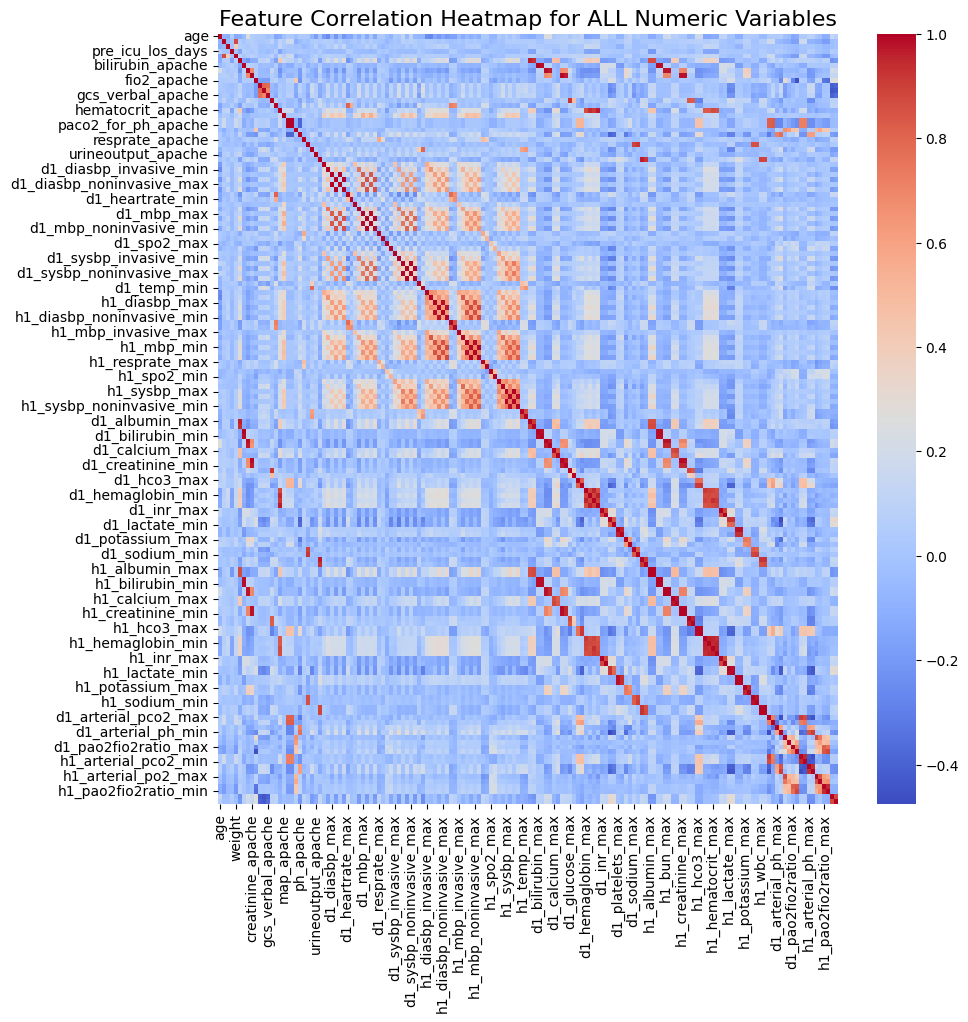

In [6]:
all_numeric_cols = [
    col for col in df.columns 
    if col in col_types and col_types[col] in ("integer", "numeric")
]

cols_to_exclude = [
    'encounter_id', 'patient_id', 'hospital_id', 'icu_id', 'hospital_death'
]
numeric_cols_for_corr = [col for col in all_numeric_cols if col not in cols_to_exclude]

correlation_matrix = df[numeric_cols_for_corr].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False)
plt.title('Feature Correlation Heatmap for ALL Numeric Variables', fontsize=16) # Updated title
plt.show()


## Class imbalance in Target Variable

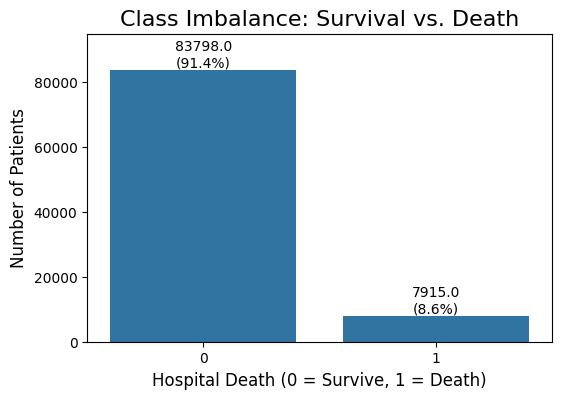

In [7]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='hospital_death', data=df)
plt.title('Class Imbalance: Survival vs. Death', fontsize=16)
plt.xlabel('Hospital Death (0 = Survive, 1 = Death)', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.ylim(0, 95000)
total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 3, f'{height}\n({height/total:.1%})', ha="center", va="bottom")
plt.show()

## Missing Data in Predictor Variables

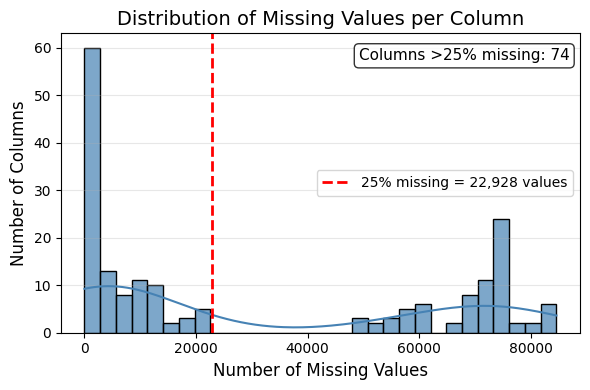

In [8]:
missing_counts = df.isnull().sum()
threshold = df.shape[0] * 0.25
n_exceed = (missing_counts > threshold).sum()

plt.figure(figsize=(6, 4))
ax = sns.histplot(missing_counts, bins=30, kde=True, color='steelblue', edgecolor='k', alpha=0.7)
ax.axvline(threshold, color='red', linestyle='--', linewidth=2, label=f'25% missing = {int(threshold):,} values')
ax.set_title("Distribution of Missing Values per Column", fontsize=14)
ax.set_xlabel("Number of Missing Values", fontsize=12)
ax.set_ylabel("Number of Columns", fontsize=12)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# show count of columns above the threshold
ax.text(
    0.98, 0.95,
    f"Columns >25% missing: {n_exceed}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.show()

## Distribution of Hospital Mortality Rates

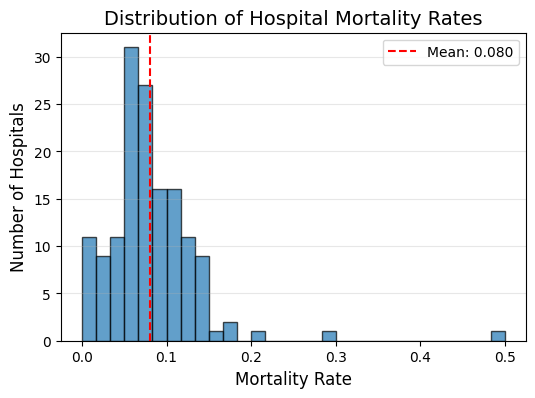

In [9]:
plt.figure(figsize=(6, 4))
all_hospital_stats = df.groupby('hospital_id')['hospital_death'].mean()
plt.hist(all_hospital_stats, bins=30, edgecolor='black', alpha=0.7)
plt.title('Distribution of Hospital Mortality Rates', fontsize=14)
plt.xlabel('Mortality Rate', fontsize=12)
plt.ylabel('Number of Hospitals', fontsize=12)
plt.axvline(all_hospital_stats.mean(), color='red', linestyle='--', 
            label=f'Mean: {all_hospital_stats.mean():.3f}')
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Data Cleaning 
## Dropping High-Missingness Columns

In [10]:
# Initial data cleaning: drop columns with >25% missing
df = df.drop(df.isnull().sum()[df.isnull().sum() > df.shape[0] * 0.25].index, axis=1)

df.shape

(91713, 112)

In [11]:
num_cols = set()
cat_cols = set()
for col in df.columns:
    if col_types[col] in ("integer", "numeric"):
        num_cols.add(col)
    else:
        cat_cols.add(col)

In [12]:
missingness_predictor_cols = []
ignored = [
    "encounter_id",
    "patient_id",
    'icu_id',
    'hospital_id',
    "hospital_death",
    "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob",
]
list_of_zero_missing_cols = df.columns[df.isnull().sum() == 0].to_list()
for col in list_of_zero_missing_cols:
    if col not in ignored:
        missingness_predictor_cols.append(col)

print(missingness_predictor_cols)

['elective_surgery', 'icu_stay_type', 'icu_type', 'pre_icu_los_days', 'readmission_status', 'apache_post_operative']


In [13]:
# Add missingness indicator features
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[f"{col}_missing"] = df[col].isnull().astype(int)

df = df.copy()

In [14]:
X = df[missingness_predictor_cols]
missingness_indicator_cols = [col for col in df.columns if col.endswith("_missing")]
y_df = df[missingness_indicator_cols]

print(X.columns)

Index(['elective_surgery', 'icu_stay_type', 'icu_type', 'pre_icu_los_days',
       'readmission_status', 'apache_post_operative'],
      dtype='object')


## Diagnosing Patterns of Missingness

In [15]:
# Correctly identify numeric and categorical columns that are PRESENT in X
num_cols_in_X = [col for col in X.columns if col in num_cols]
cat_cols_in_X = [col for col in X.columns if col in cat_cols]

# Now define the preprocessor using these filtered lists
pre_processor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_in_X),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_in_X)
    ],
    remainder='passthrough'
)

missingness_auroc = {}

for col in missingness_indicator_cols:
    y = y_df[col]

    model = Pipeline(steps=[
        ('preprocessor', pre_processor),
        ('classifier', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42))
    ])
    model.fit(X, y)

    y_pred_prob = model.predict_proba(X)[:, 1]
    auroc = roc_auc_score(y, y_pred_prob)
    missingness_auroc[col] = auroc

auroc_df = pd.DataFrame.from_dict(missingness_auroc, orient='index', columns=['AUROC'])
auroc_df = auroc_df.sort_values(by='AUROC', ascending=False)

In [16]:
# Impute missing values for rows with high missingness AUROC with KNN Imputer
missingness_auroc_threshold = 0.75

high_auroc_cols = auroc_df[auroc_df['AUROC'] >= missingness_auroc_threshold].index.tolist()
low_auroc_cols = auroc_df[auroc_df['AUROC'] < missingness_auroc_threshold].index.tolist()

print(len(high_auroc_cols))
print(len(low_auroc_cols))

25
76


In [17]:
df_pre_impute = df.copy()

In [18]:
for col in low_auroc_cols:
    col_name = col.replace("_missing", "")
    if col_name in num_cols:
        df[col_name] = SimpleImputer(strategy='median').fit_transform(df[[col_name]])[:, 0]
    elif col_name in cat_cols:
        df[col_name] = SimpleImputer(strategy='most_frequent').fit_transform(df[[col_name]])[:, 0]
    else:
        raise ValueError(f"Column {col_name} not found in numeric or categorical features.")

for col in high_auroc_cols:
    col_name = col.replace("_missing", "")
    if col_name in cat_cols:
        df[col_name] = SimpleImputer(strategy='most_frequent').fit_transform(df[[col_name]])[:, 0]
    elif col_name in num_cols:
        df[col_name] = KNNImputer(n_neighbors=5).fit_transform(df[[col_name]])[:, 0]
    else:
        raise ValueError(f"Column {col_name} not found in numeric or categorical features.")


In [19]:
# Drop missing indicator columns for feature selection
df_no_missing_indicators = df.drop(columns=missingness_indicator_cols)
df_no_missing_indicators = df_no_missing_indicators.drop(columns=ignored)

df_imputed = df_no_missing_indicators.copy()

# EDA 2 (Effect of Imputation on Data Distribution)

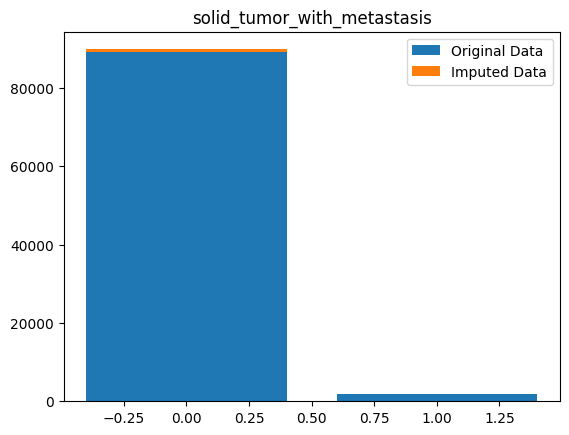

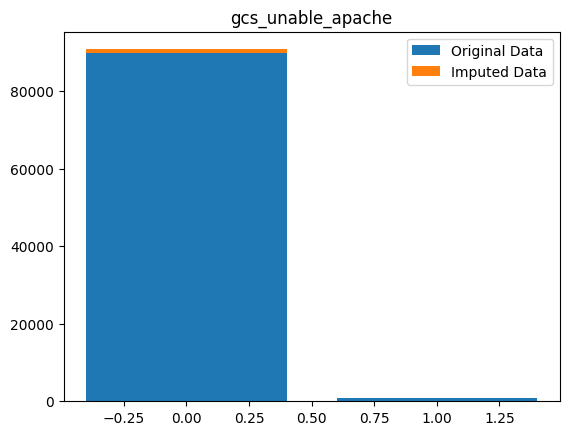

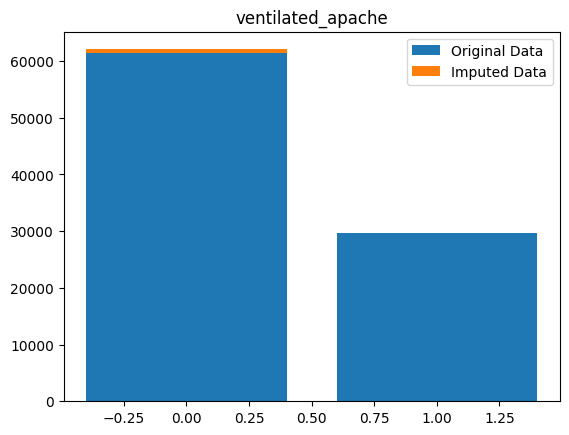

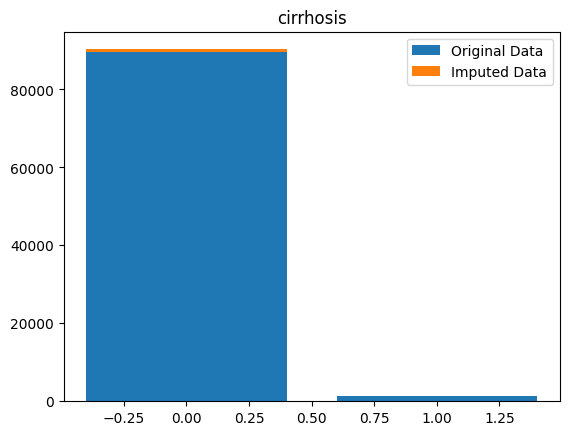

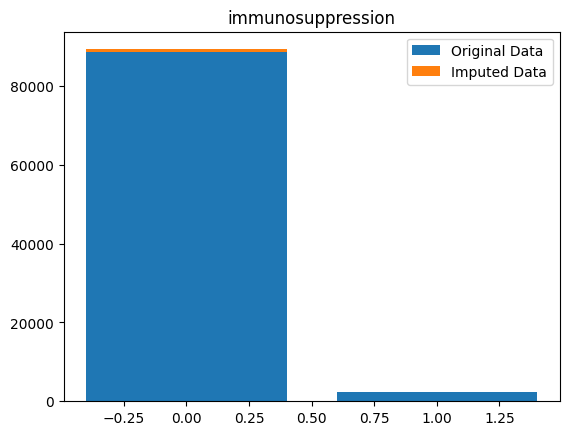

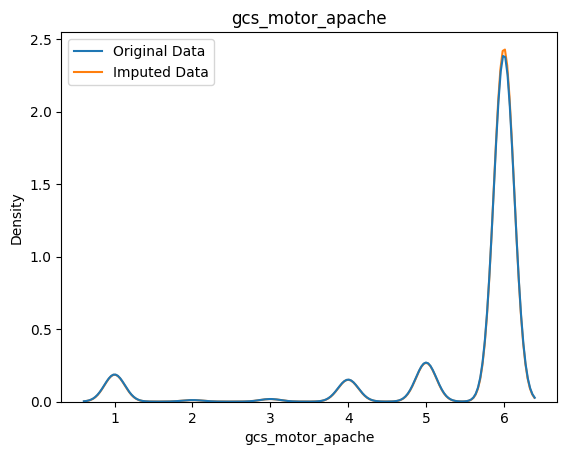

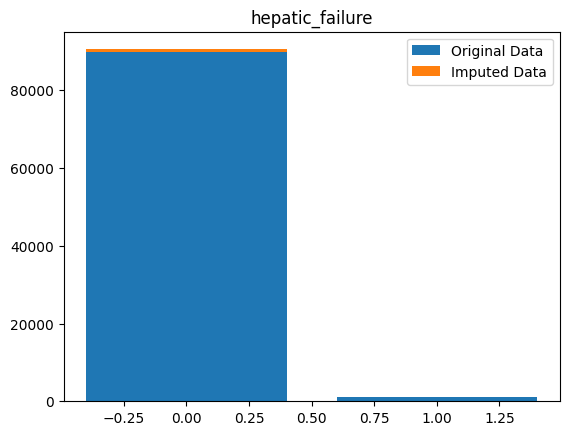

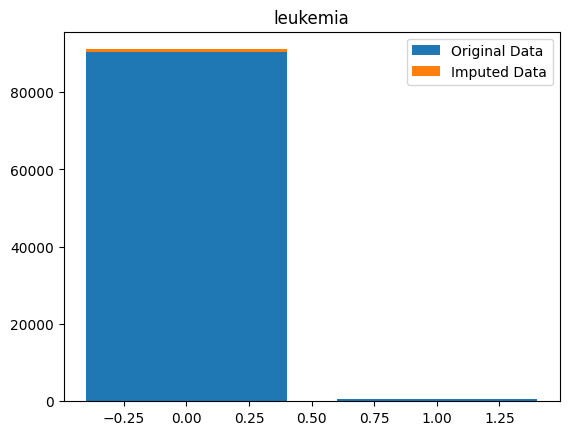

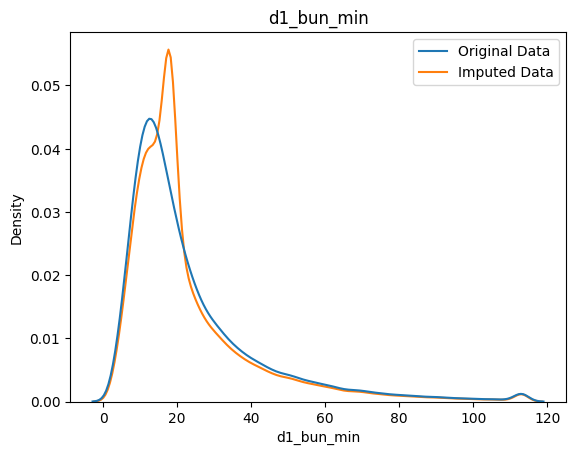

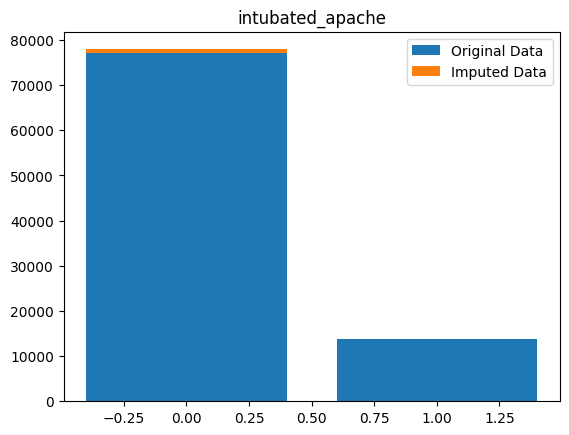

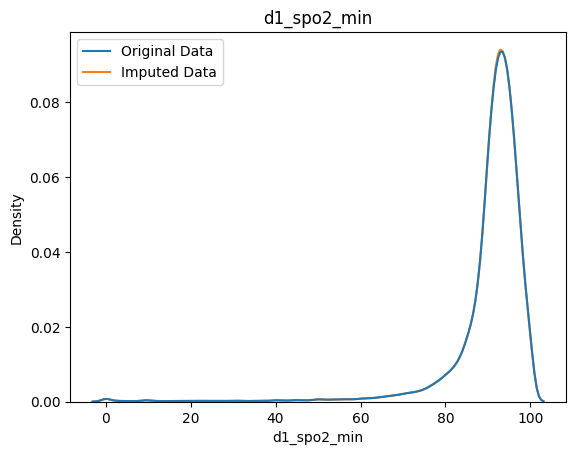

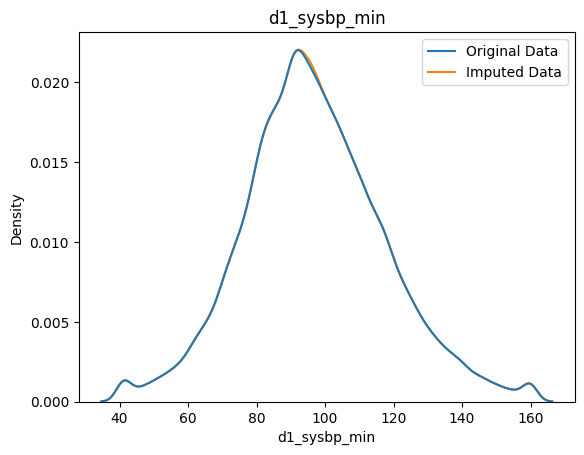

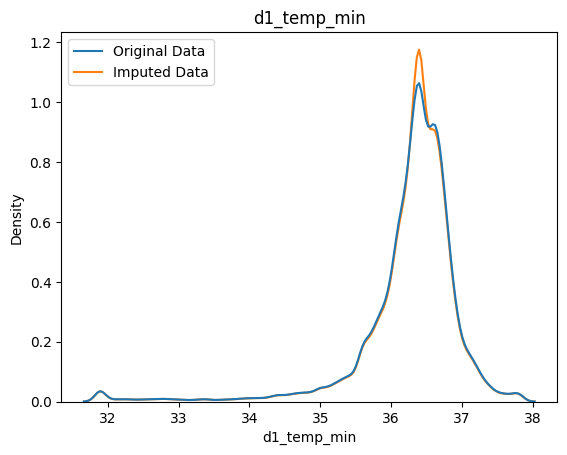

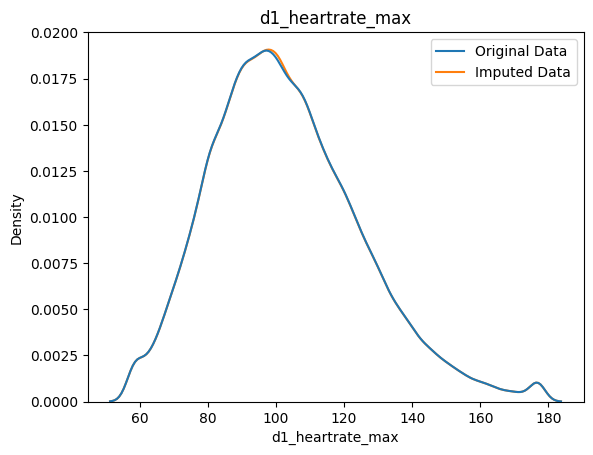

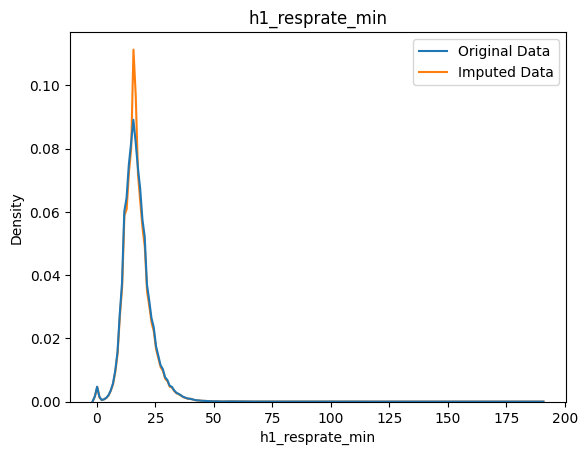

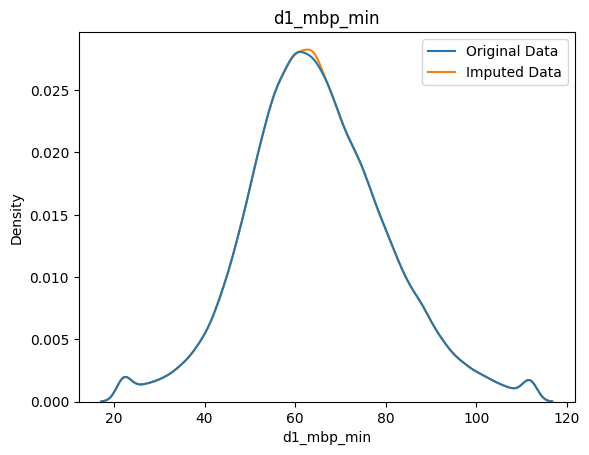

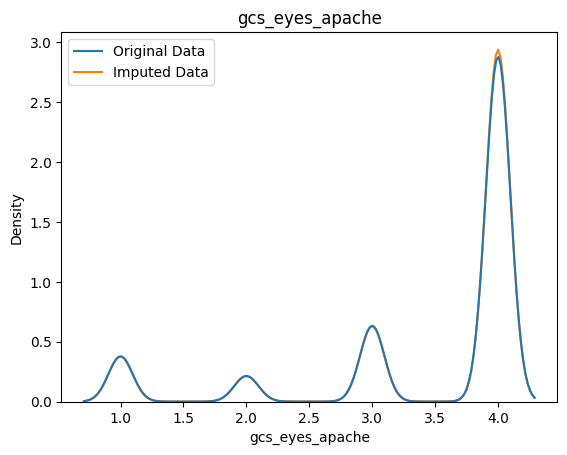

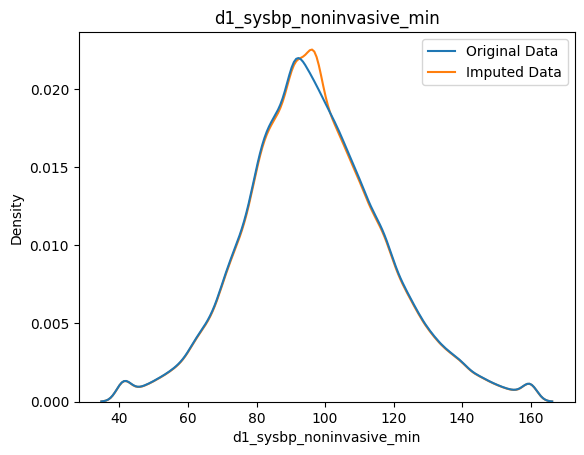

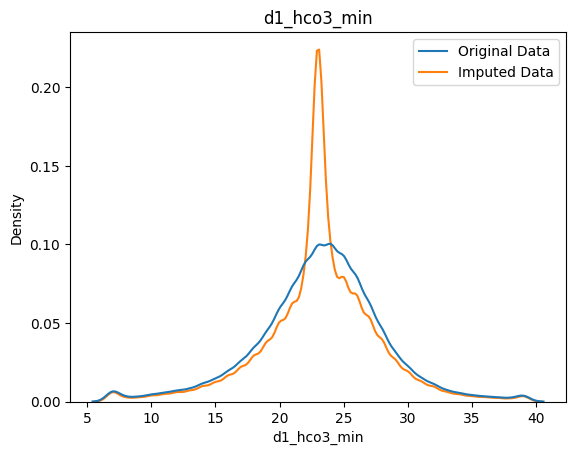

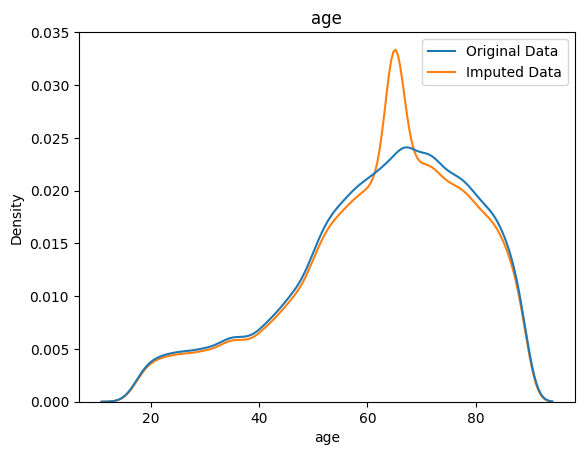

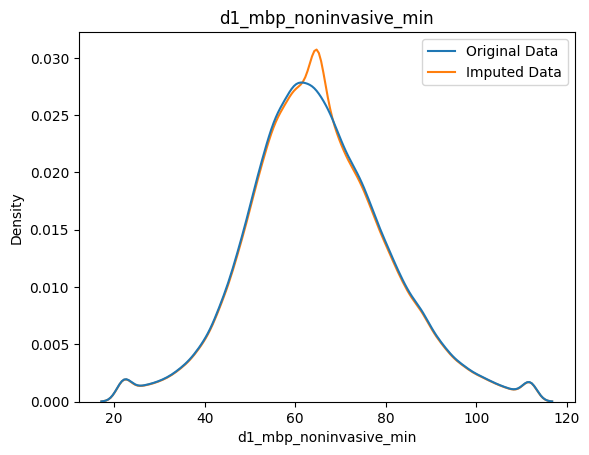

In [20]:
# Simple visualization of columns

cols_of_interest = [
    "solid_tumor_with_metastasis",
    "gcs_unable_apache",
    "ventilated_apache",
    "cirrhosis",
    "immunosuppression",
    "gcs_motor_apache",
    "hepatic_failure",
    "leukemia",
    "d1_bun_min",
    "intubated_apache",
    "d1_spo2_min",
    "d1_sysbp_min",
    "d1_temp_min",
    "d1_heartrate_max",
    "h1_resprate_min",
    "d1_mbp_min",
    "gcs_eyes_apache",
    "d1_sysbp_noninvasive_min",
    "d1_hco3_min",
    "age",
    "d1_mbp_noninvasive_min",
]

# Use the pre-imputation dataframe for the following EDA cells
# (this will overwrite `df` in the notebook kernel so subsequent cells use df_pre_impute)
df = df_pre_impute

for col in cols_of_interest:
    if col in cat_cols:
        df_value_counts = df[col].value_counts()
        df_imputed_value_counts = df_imputed[col].value_counts()
        plt.bar(
            x=df_value_counts.index,
            height=df_value_counts.values,
            zorder=1,
            label="Original Data",
        )
        plt.bar(
            x=df_imputed_value_counts.index,
            height=df_imputed_value_counts.values,
            zorder=0,
            label="Imputed Data",
        )
    else:
        sns.kdeplot(df[col].dropna(), label="Original Data", zorder=1)
        sns.kdeplot(df_imputed[col].dropna(), label="Imputed Data", zorder=0)
    plt.title(col)
    plt.legend()
    plt.show()


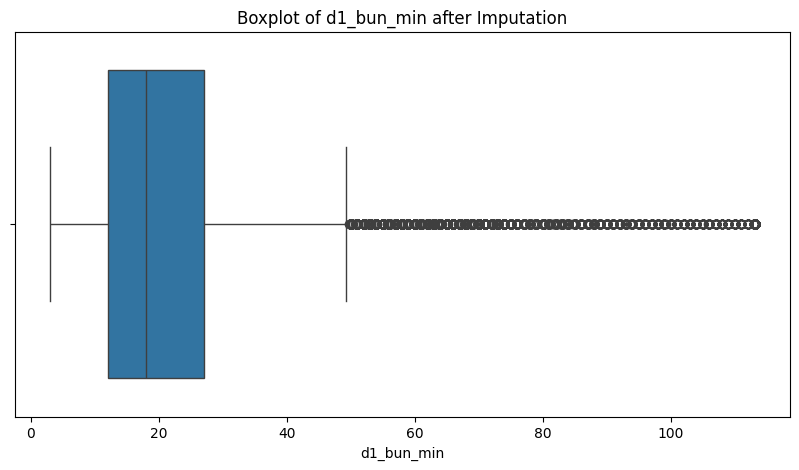

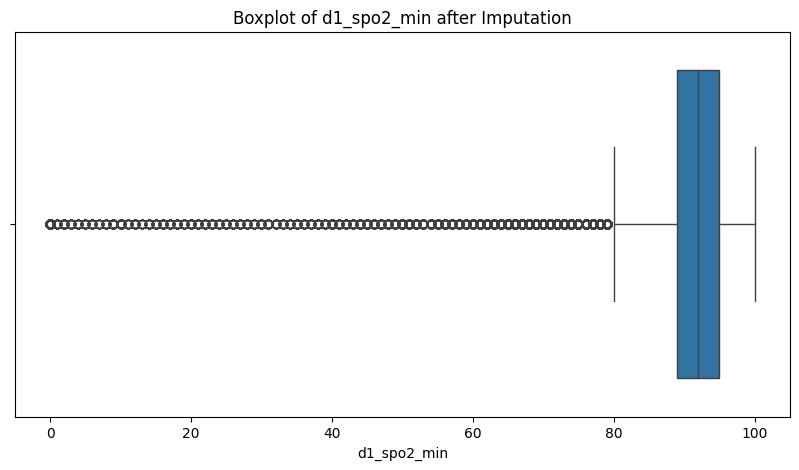

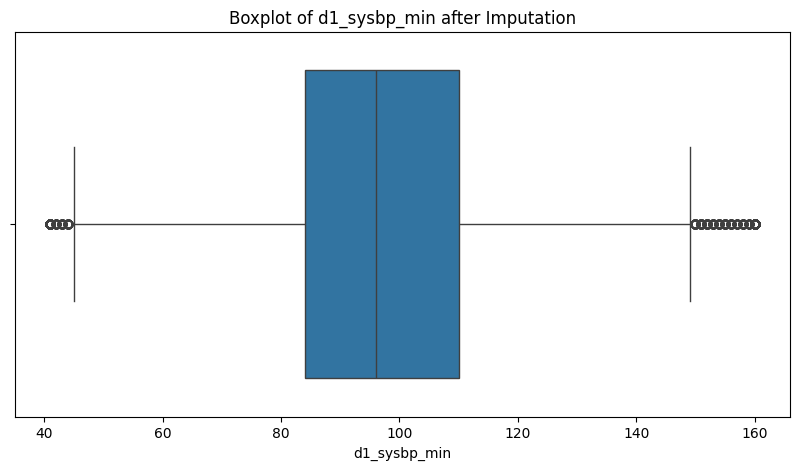

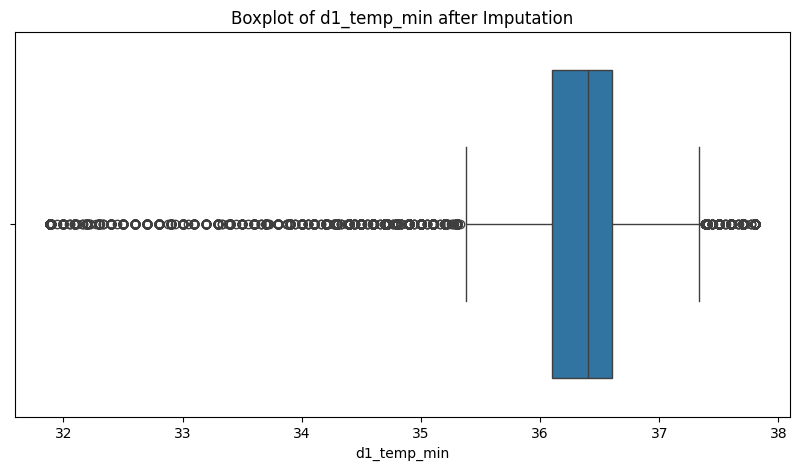

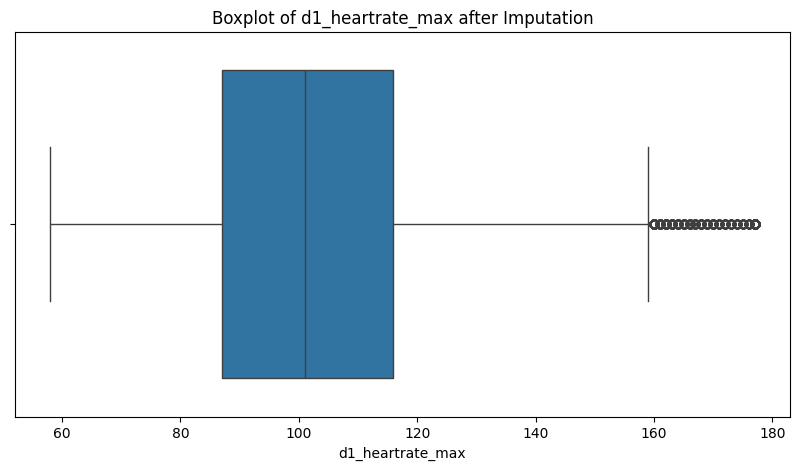

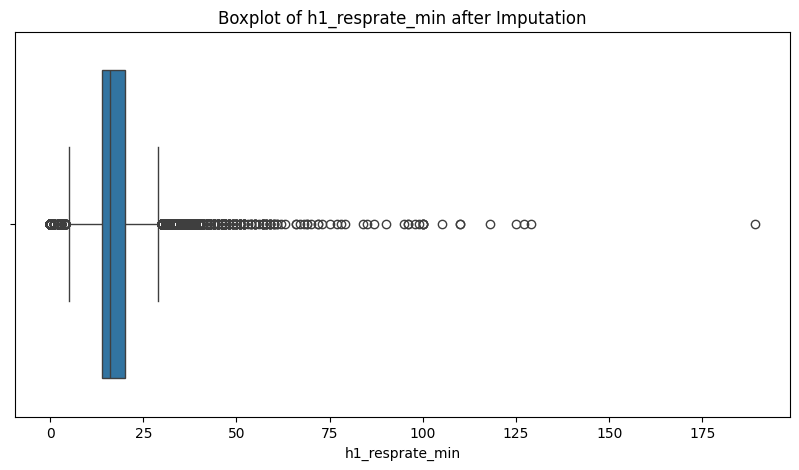

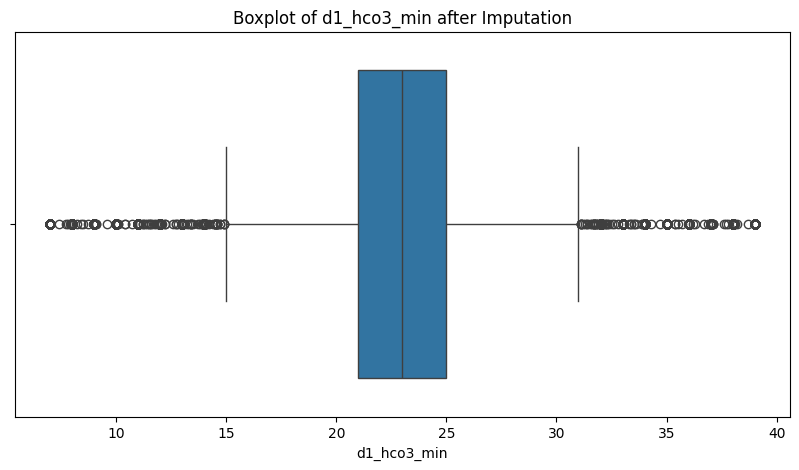

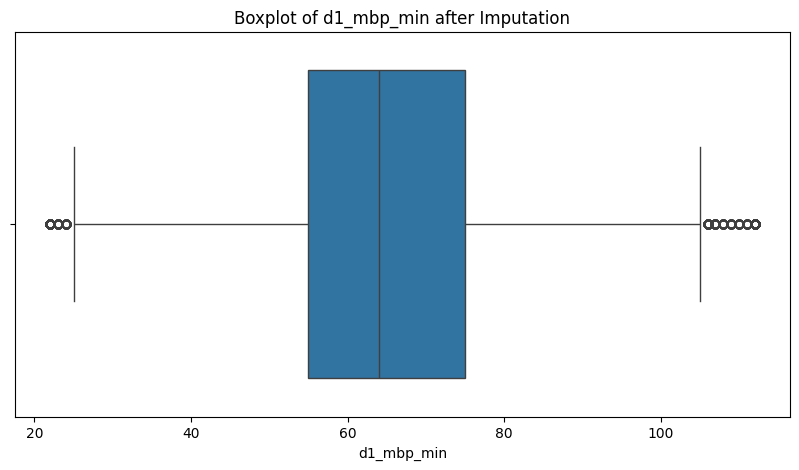

In [21]:
candidate_outlier_cols = [
    "d1_bun_min",
    "d1_spo2_min",
    "d1_sysbp_min",
    "d1_temp_min",
    "d1_heartrate_max",
    "h1_resprate_min",
    "d1_hco3_min",
    "d1_mbp_min",
]

for col in candidate_outlier_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df_imputed[col])
    plt.title(f"Boxplot of {col} after Imputation")
    plt.show()


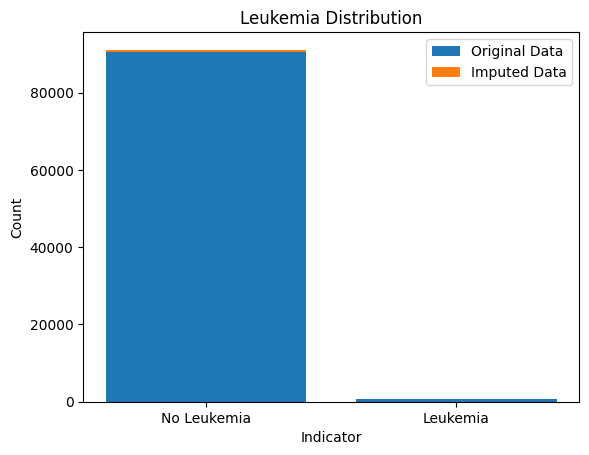

In [22]:
leuk_value_counts = df["leukemia"].value_counts()
leuk_imputed_value_counts = df_imputed["leukemia"].value_counts()
plt.bar(
    x=leuk_value_counts.index,
    height=leuk_value_counts.values,
    zorder=1,
    label="Original Data",
)
plt.bar(
    x=leuk_imputed_value_counts.index,
    height=leuk_imputed_value_counts.values,
    zorder=0,
    label="Imputed Data",
)
plt.title("Leukemia Distribution")
plt.legend()
plt.xticks([0, 1], ["No Leukemia", "Leukemia"])
plt.ylabel("Count")
plt.xlabel("Indicator")
plt.show()

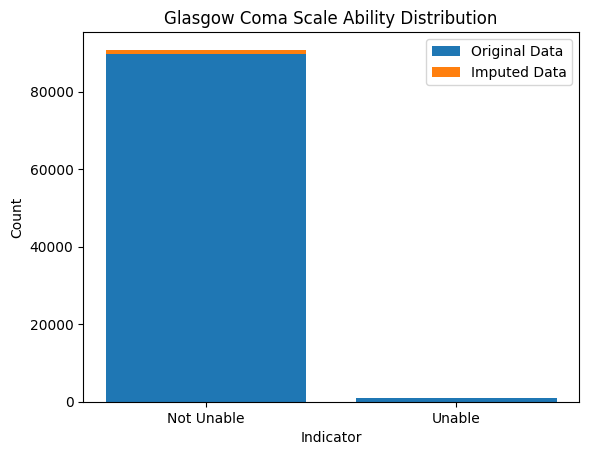

In [23]:
gcs_value_counts = df["gcs_unable_apache"].value_counts()
gcs_imputed_value_counts = df_imputed["gcs_unable_apache"].value_counts()
plt.bar(
    x=gcs_value_counts.index,
    height=gcs_value_counts.values,
    zorder=1,
    label="Original Data",
)
plt.bar(
    x=gcs_imputed_value_counts.index,
    height=gcs_imputed_value_counts.values,
    zorder=0,
    label="Imputed Data",
)
plt.title("Glasgow Coma Scale Ability Distribution")
plt.legend()
plt.xticks([0, 1], ["Not Unable", "Unable"])
plt.ylabel("Count")
plt.xlabel("Indicator")
plt.show()



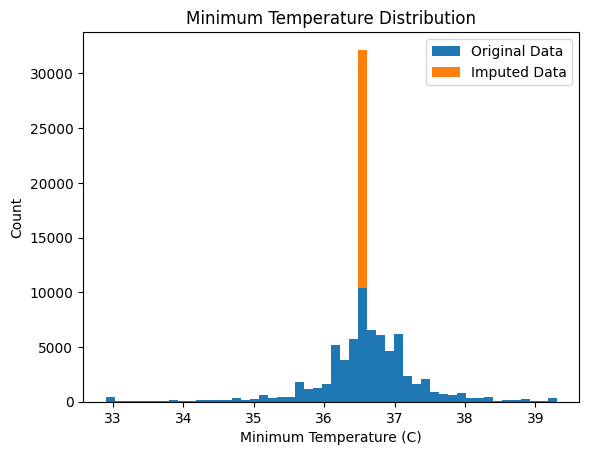

In [24]:
plt.hist(
    x=df["h1_temp_min"],
    bins=50,
    zorder=1,
    label="Original Data",
)
plt.hist(
    x=df_imputed["h1_temp_min"],
    bins=50,
    zorder=0,
    label="Imputed Data",
)
plt.title("Minimum Temperature Distribution")
plt.legend()
plt.ylabel("Count")
plt.xlabel("Minimum Temperature (C)")
plt.show()


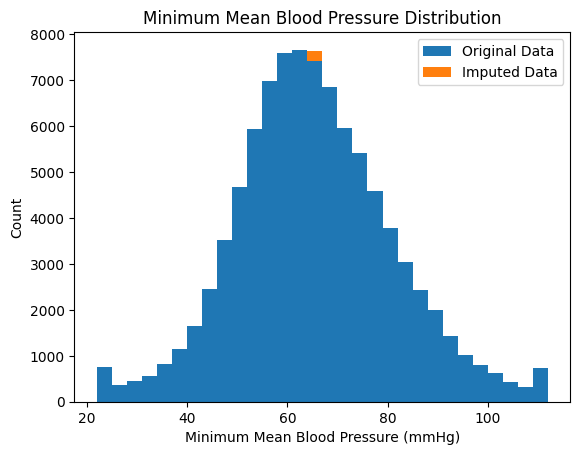

In [25]:
plt.hist(
    x=df["d1_mbp_min"],
    bins=30,
    zorder=1,
    label="Original Data",
)
plt.hist(
    x=df_imputed["d1_mbp_min"],
    bins=30,
    zorder=0,
    label="Imputed Data",
)
plt.title("Minimum Mean Blood Pressure Distribution")
plt.legend()
plt.ylabel("Count")
plt.xlabel("Minimum Mean Blood Pressure (mmHg)")
plt.show()


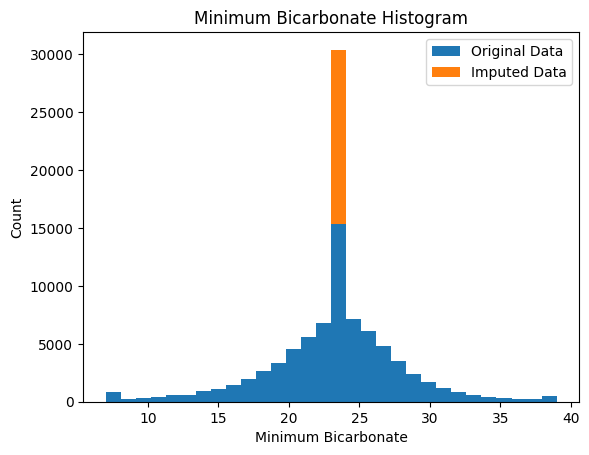

In [26]:
plt.hist(
    x=df["d1_hco3_min"],
    bins=30,
    zorder=1,
    label="Original Data",
)
plt.hist(
    x=df_imputed["d1_hco3_min"],
    bins=30,
    zorder=0,
    label="Imputed Data",
)
plt.title("Minimum Bicarbonate Histogram")
plt.legend()
plt.ylabel("Count")
plt.xlabel("Minimum Bicarbonate")
plt.show()


# Lasso Regression for Feature Selection

In [27]:
from sklearn.pipeline import Pipeline

lambdas = np.logspace(-4, 4, 50)
coeffs = []
results = []

X = df_no_missing_indicators
y = df["hospital_death"].loc[X.index]

num_cols_for_model = [col for col in num_cols if col in X.columns and col not in ignored]
cat_cols_for_model = [col for col in cat_cols if col in X.columns and col not in ignored]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_for_model),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_for_model)
    ],
    remainder='passthrough'
)


for i, l in enumerate(lambdas):
    print(f"Processing {i}th lambda: {l}")
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            penalty="l1", C=l, solver="liblinear", random_state=42, max_iter=1000
        ))
    ])
    
    pipeline.fit(X, y)
    
    model_coeffs = pipeline.named_steps['classifier'].coef_[0]
    
    # On the first loop, get the feature names from the preprocessor
    if i == 0:
        ohe_feature_names = pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_cols_for_model)
        # This combines numeric columns and the new one-hot encoded columns
        all_feature_names = num_cols_for_model + list(ohe_feature_names)

    coeffs.append(model_coeffs)

# Now, we need to update the feature names in the final dataframe `X` to match what the model saw
# This is important for the next step where you zip names and coeffs
X_processed = pd.DataFrame(preprocessor.fit_transform(X), columns=all_feature_names, index=X.index)
X_processed.columns = X_processed.columns.astype(str)
X = X_processed # Replace X with the fully processed version

Processing 0th lambda: 0.0001
Processing 1th lambda: 0.00014563484775012445
Processing 2th lambda: 0.00021209508879201905
Processing 3th lambda: 0.00030888435964774815
Processing 4th lambda: 0.0004498432668969444
Processing 5th lambda: 0.0006551285568595509
Processing 6th lambda: 0.0009540954763499944
Processing 7th lambda: 0.0013894954943731374
Processing 8th lambda: 0.0020235896477251557
Processing 9th lambda: 0.0029470517025518097
Processing 10th lambda: 0.004291934260128779
Processing 11th lambda: 0.0062505519252739694
Processing 12th lambda: 0.009102981779915217
Processing 13th lambda: 0.013257113655901081
Processing 14th lambda: 0.019306977288832496
Processing 15th lambda: 0.02811768697974228
Processing 16th lambda: 0.040949150623804234
Processing 17th lambda: 0.05963623316594643
Processing 18th lambda: 0.08685113737513521
Processing 19th lambda: 0.12648552168552957
Processing 20th lambda: 0.18420699693267145
Processing 21th lambda: 0.2682695795279725
Processing 22th lambda: 0.39

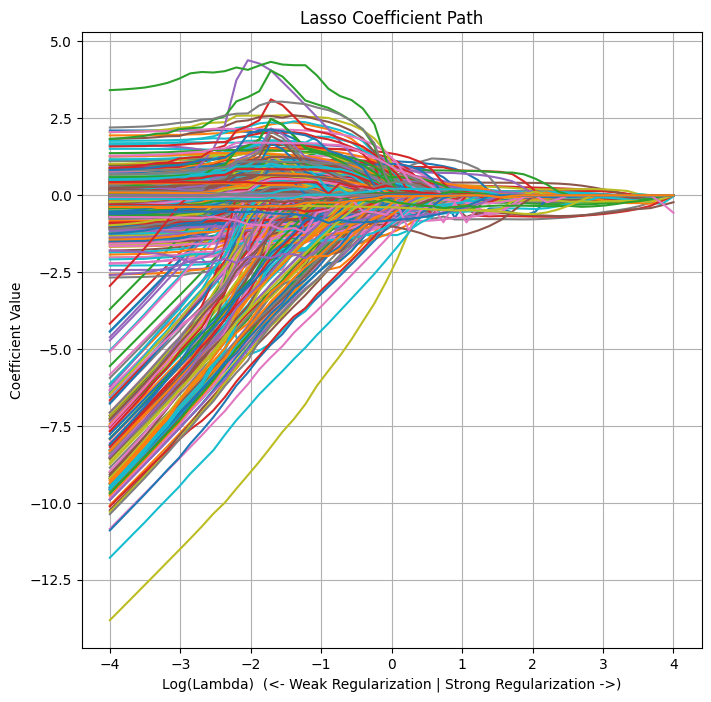

In [28]:
coeffs_array = np.array(coeffs)
actual_lambdas = 1 / lambdas
x_axis = np.log10(actual_lambdas)

plt.figure(figsize=(8, 8))
for i in range(coeffs_array.shape[1]):
    plt.plot(x_axis, coeffs_array[:, i])

plt.xlabel("Log(Lambda)  (<- Weak Regularization | Strong Regularization ->)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficient Path")

plt.grid(True)
plt.show()


In [29]:
print(coeffs_array.shape)

(50, 612)


In [30]:
sorted(zip(np.abs(coeffs_array[3,:]), X.columns), reverse=True)

[(np.float64(0.4481636897491921), 'gcs_unable_apache_0.0'),
 (np.float64(0.436858955111851), 'solid_tumor_with_metastasis_0.0'),
 (np.float64(0.3552616797036965), 'ventilated_apache_0.0'),
 (np.float64(0.2540874264002638), 'leukemia_0.0'),
 (np.float64(0.19335685620255258), 'hepatic_failure_0.0'),
 (np.float64(0.1916450296141107), 'cirrhosis_0.0'),
 (np.float64(0.17972921704298583), 'intubated_apache_0.0'),
 (np.float64(0.17887690233684447), 'gcs_motor_apache'),
 (np.float64(0.15954394930756358), 'immunosuppression_0.0'),
 (np.float64(0.0977361324079872), 'd1_spo2_min'),
 (np.float64(0.08578076549030167), 'd1_sysbp_min'),
 (np.float64(0.03814365603580292), 'd1_temp_min'),
 (np.float64(0.03321001113909886), 'd1_bun_min'),
 (np.float64(0.032671321435718305), 'd1_bun_max'),
 (np.float64(0.0), 'weight'),
 (np.float64(0.0), 'wbc_apache'),
 (np.float64(0.0), 'ventilated_apache_1.0'),
 (np.float64(0.0), 'temp_apache'),
 (np.float64(0.0), 'solid_tumor_with_metastasis_1.0'),
 (np.float64(0.0), 

In [32]:
for i in range(10):
    print(f"--- Lambda Index: {i}, C={lambdas[i]:.4f}, Actual Lambda={1/lambdas[i]:.2f} ---")
    
    current_coeffs = coeffs_array[i]
    feature_coef_pairs = zip(X.columns, current_coeffs)
    
    non_zero_coeffs = [
        (name, coef) for name, coef in feature_coef_pairs if np.abs(coef) > 1e-5
    ]
    
    sorted_coeffs = sorted(non_zero_coeffs, key=lambda x: np.abs(x[1]), reverse=True)
    
    if not sorted_coeffs:
        print("All coefficients are zero.")
    else:
        print(f"{len(sorted_coeffs)} non-zero coefficients:")
        for name, coef in sorted_coeffs:
            print(f"  {name}: {coef:.6f}")
    print("\n")

--- Lambda Index: 0, C=0.0001, Actual Lambda=10000.00 ---
3 non-zero coefficients:
  readmission_status_0: -0.571576
  gcs_unable_apache_0.0: -0.227372
  intubated_apache_0.0: -0.035622


--- Lambda Index: 1, C=0.0001, Actual Lambda=6866.49 ---
9 non-zero coefficients:
  gcs_unable_apache_0.0: -0.327232
  intubated_apache_0.0: -0.283469
  readmission_status_0: -0.258470
  solid_tumor_with_metastasis_0.0: -0.182610
  leukemia_0.0: -0.179619
  hepatic_failure_0.0: -0.126008
  lymphoma_0.0: -0.059690
  ventilated_apache_0.0: -0.036873
  cirrhosis_0.0: -0.030358


--- Lambda Index: 2, C=0.0002, Actual Lambda=4714.87 ---
11 non-zero coefficients:
  gcs_unable_apache_0.0: -0.418106
  solid_tumor_with_metastasis_0.0: -0.345882
  leukemia_0.0: -0.275834
  ventilated_apache_0.0: -0.243198
  intubated_apache_0.0: -0.237047
  hepatic_failure_0.0: -0.201452
  cirrhosis_0.0: -0.141783
  gcs_motor_apache: -0.106593
  immunosuppression_0.0: -0.078040
  lymphoma_0.0: -0.053880
  d1_spo2_min: -0.023743

In [59]:
current_coeffs = coeffs_array[4]

feature_coef_pairs = zip(X.columns, current_coeffs)

non_zero_coeffs = [
    (name, coef) for name, coef in feature_coef_pairs if np.abs(coef) > 1e-5
]

non_zero_coeffs

[('gcs_motor_apache', np.float64(-0.21234717896607036)),
 ('d1_heartrate_max', np.float64(0.04577158164289624)),
 ('d1_mbp_min', np.float64(-0.037835804503407275)),
 ('d1_mbp_noninvasive_min', np.float64(-0.0001936264113909313)),
 ('d1_spo2_min', np.float64(-0.1359169361402756)),
 ('d1_hco3_min', np.float64(-0.009203790910636486)),
 ('d1_temp_min', np.float64(-0.08679279235361356)),
 ('h1_resprate_min', np.float64(0.038096349029417824)),
 ('age', np.float64(0.0074263102060576035)),
 ('d1_bun_min', np.float64(0.1380757757498847)),
 ('d1_sysbp_noninvasive_min', np.float64(-0.02302223314267638)),
 ('gcs_eyes_apache', np.float64(-0.01633442322642824)),
 ('d1_sysbp_min', np.float64(-0.100324400235944)),
 ('immunosuppression_0.0', np.float64(-0.20186245692087798)),
 ('ventilated_apache_0.0', np.float64(-0.43828586502082806)),
 ('intubated_apache_0.0', np.float64(-0.13620079975183125)),
 ('leukemia_0.0', np.float64(-0.25607862209951454)),
 ('solid_tumor_with_metastasis_0.0', np.float64(-0.509

In [60]:
selected_features = [name for name, coef in non_zero_coeffs]
X_selected = X[selected_features].copy()
X_selected.head()

,gcs_motor_apache,d1_heartrate_max,d1_mbp_min,d1_mbp_noninvasive_min,d1_spo2_min,d1_hco3_min,d1_temp_min,h1_resprate_min,age,d1_bun_min,...,gcs_eyes_apache,d1_sysbp_min,immunosuppression_0.0,ventilated_apache_0.0,intubated_apache_0.0,leukemia_0.0,solid_tumor_with_metastasis_0.0,gcs_unable_apache_0.0,hepatic_failure_0.0,cirrhosis_0.0
0,0.405462,0.727392,-1.204902,-1.216220,-1.644035,-1.784322,1.261358,0.142618,0.339552,0.387708,...,-0.503917,-1.157907,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,-1.943480,0.681937,-1.715730,-1.729894,-2.043546,0.626192,-1.592165,1.828346,0.888550,-0.793348,...,-2.620603,-1.448324,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0
2,0.405462,-0.318064,0.199876,0.196381,0.053891,-0.031221,0.581948,-0.194528,-2.283438,-0.287181,...,-0.503917,0.390986,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,0.405462,0.591028,1.221533,1.223728,0.453402,-0.031221,-1.999811,-1.037392,1.132549,-0.287181,...,0.554426,-0.625475,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
4,0.405462,-0.636247,1.604655,1.608983,0.553280,-0.031221,0.581948,-0.194528,-2.649436,-0.287181,...,0.554426,1.117029,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


# Multi-Collinearity of Top Features

<Figure size 1600x1200 with 0 Axes>

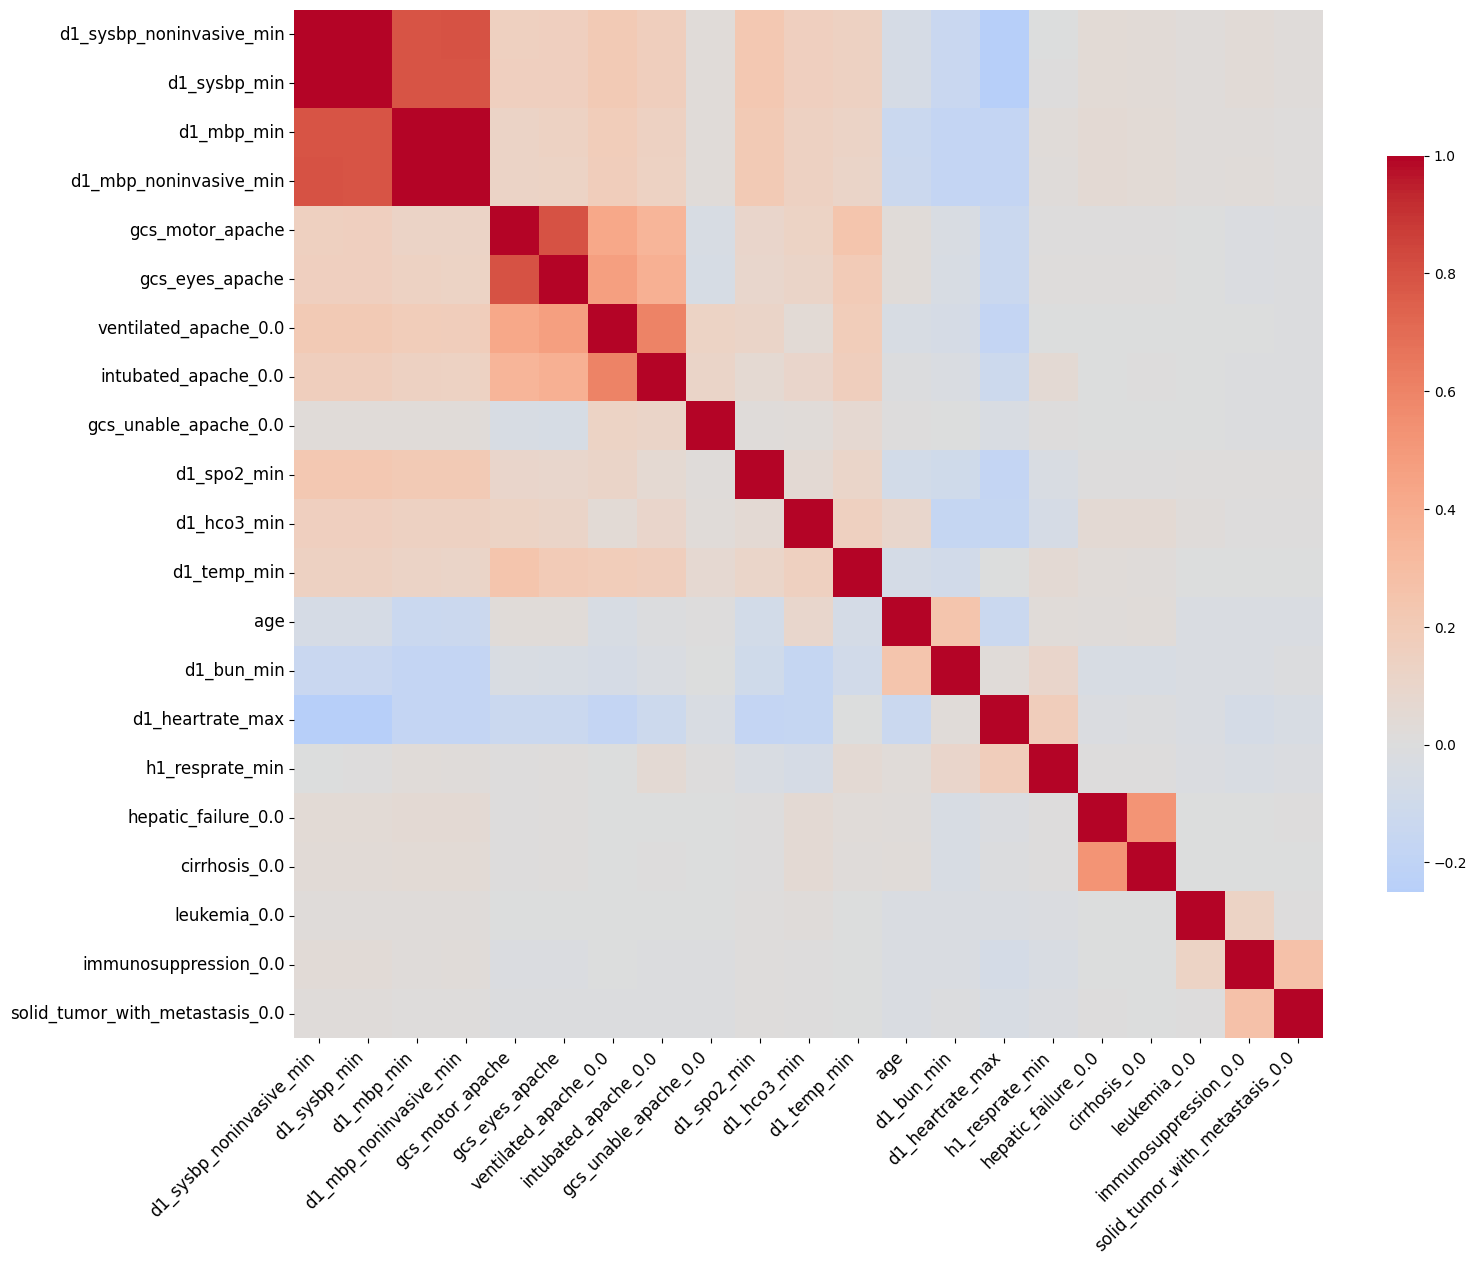

In [61]:
from scipy.cluster.hierarchy import linkage, leaves_list

num_df = X_selected.select_dtypes(include='number')

plt.figure(figsize=(16, 12))
corr = num_df.corr()

#===== Create a clustered heatmap that does not look as complicated as sns.clustermap()
row_linkage = linkage(corr, method="average")
col_linkage = linkage(corr.T, method="average")

row_order = leaves_list(row_linkage)
col_order = leaves_list(col_linkage)

corr_reordered = corr.iloc[row_order, col_order]

plt.figure(figsize=(16, 16))

sns.heatmap(
    corr_reordered,
    cmap="coolwarm",
    center=0,
    square=True,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'shrink': 0.5} 
)

plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

# VIF Score of Top Features

In [62]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import math

#===== This block produces a tall VIF table
num_df = num_df.loc[:, num_df.nunique() > 1] 

scaled = StandardScaler().fit_transform(num_df)
scaled_df = pd.DataFrame(scaled, columns=num_df.columns)

vif_data = pd.DataFrame({
    "feature": scaled_df.columns,
    "VIF": [variance_inflation_factor(scaled_df.values, i)
            for i in range(scaled_df.shape[1])]
})

#===== Split it into 3 side-by-side columns to fit better in the doc
vif_sorted = vif_data.sort_values("VIF", ascending=False).reset_index(drop=True)

n_blocks = 3

rows_per_block = math.ceil(len(vif_sorted) / n_blocks)

blocks = []

for i in range(n_blocks):
    block = vif_sorted.iloc[i*rows_per_block : (i+1)*rows_per_block]
    block = block.reset_index(drop=True)
    blocks.append(block)

vif_3col = pd.concat(blocks, axis=1)
vif_3col

,feature,VIF,feature,VIF,feature,VIF
0,d1_sysbp_noninvasive_min,95.805603,intubated_apache_0.0,1.649647,d1_hco3_min,1.122899
1,d1_sysbp_min,94.607378,hepatic_failure_0.0,1.385902,immunosuppression_0.0,1.104354
2,d1_mbp_noninvasive_min,76.527622,cirrhosis_0.0,1.385572,d1_spo2_min,1.094054
3,d1_mbp_min,75.186678,d1_heartrate_max,1.198955,solid_tumor_with_metastasis_0.0,1.082204
4,gcs_eyes_apache,3.018682,age,1.142376,h1_resprate_min,1.060167
5,gcs_motor_apache,2.877648,d1_bun_min,1.138697,gcs_unable_apache_0.0,1.047007
6,ventilated_apache_0.0,1.874987,d1_temp_min,1.128697,leukemia_0.0,1.021712


# Logistic Regression Model

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score

cols_to_drop = ["d1_sysbp_min", "d1_sysbp_noninvasive_min", "d1_mbp_noninvasive_min"]
X_selected = X_selected.drop(columns=cols_to_drop)

num_cols = X_selected.select_dtypes(include='number').columns
cat_cols = X_selected.select_dtypes(exclude='number').columns

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=10000, solver='lbfgs'))
])

pipe.fit(X_train, y_train)

pred = pipe.predict(X_test)
pred_proba = pipe.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("F1-score:", f1_score(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, pred_proba))
print("Precision:",precision_score(y_test, pred))
print("Recall:",recall_score(y_test, pred))

Accuracy: 0.9216594886332661
F1-score: 0.32312764955252005
ROC AUC: 0.8591960447897334
Precision: 0.6351851851851852
Recall: 0.21667719519898926
